# ModernBERT Experiment - Dzifa, Aarabhi

**Experiment, not part of the pipeline.** Tests ModernBERT-base (`answerdotai/ModernBERT-base`: newer, general-domain, 8,192-token context) against Legal-BERT, with the same class weights (p0.5 cap 10) and learning rate 5e-5 for 15 epochs:
- `modernbert-w-p0.5-c10-dorig-k1.0`: the original 512-token chunks, so only the model changes
- `modernbert-w-p0.5-c10-dmb-k1.0`: 2,048-token chunks cut with ModernBERT's tokenizer (`data="mb"`, about 4 times fewer chunks), to use its long context

Runs are compared at **contract level** (`WINNER_METRIC = "contract_macro_f1"`), because chunk-level scores are not comparable between different chunkings.

**Result:** ModernBERT scored lower than Legal-BERT at contract level (0.700 on 512-token chunks, 0.618 on 2,048-token chunks, vs 0.771), so the pipeline keeps Legal-BERT. Details in section 9.

**How to run:** on Colab with a GPU (`RUN_MODE = "auto"`: **full** on a GPU, **smoke** on CPU). By default **Run all retrains nothing** and shows the saved results, read from your Google Drive or, if missing, from `results/training/15ep/` in the repo. To retrain, add run names to `RUNS_TO_RUN` (about 22–26 minutes each on an A100); the 2,048-token data is built on first use in `data/processed_mb/`.

## 0. Google Colab setup
On Colab: clones the repo, installs `requirements.txt`, mounts Google Drive (results are saved there). Does nothing elsewhere.

In [ ]:
import os, sys, subprocess

IN_COLAB = "google.colab" in sys.modules
REPO_URL = "https://github.com/Break-Through-Tech/Accenture-1H-contract-review-challenge.git"
REPO_BRANCH = "main"
SAVE_TO_DRIVE = True                          # Colab only: keep results/checkpoints on Google Drive

if IN_COLAB:
    repo_dir = "/content/Accenture-1H-contract-review-challenge"
    if not os.path.exists(repo_dir):
        cloned = subprocess.run(["git", "clone", "--depth", "1", "-b", REPO_BRANCH, REPO_URL, repo_dir]).returncode == 0
        if not cloned:   # branch not on GitHub (yet): main has the same data files
            print(f"Branch {REPO_BRANCH} not found, cloning main instead.")
            subprocess.run(["git", "clone", "--depth", "1", REPO_URL, repo_dir], check=True)
    os.chdir(f"{repo_dir}/notebooks/experimentation/Transformer")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "../../../requirements.txt"], check=True)
    if SAVE_TO_DRIVE:
        from google.colab import drive
        drive.mount("/content/drive")
print("In Colab:", IN_COLAB, "| working dir:", os.getcwd())

Mounted at /content/drive
In Colab: True | working dir: /content/Accenture-1H-contract-review-challenge/notebooks/pipeline


## 1. Setup

In [ ]:
import gc, json, re, shutil, time, platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import transformers
from datasets import Dataset, DatasetDict, Features, Sequence, Value, load_from_disk, disable_progress_bars
from sklearn.metrics import average_precision_score, precision_recall_fscore_support
from transformers import (AutoModelForSequenceClassification, AutoTokenizer, DataCollatorWithPadding,
                          Trainer, TrainingArguments, set_seed)
from sklearn.metrics import f1_score, precision_recall_curve

transformers.logging.set_verbosity_error()   # hide the expected "newly initialized classifier" warning
disable_progress_bars()                       # keep tokenization output short
print("torch", torch.__version__, "| transformers", transformers.__version__)

torch 2.14.1+cu130 | transformers 4.57.6


All settings. Add or remove names in `RUNS_TO_RUN` to choose which runs to train in this session (finished runs are skipped).

In [ ]:
RUN_MODE = "auto"      # "auto" (full if a GPU is available, else smoke), "full", or "smoke"
SEED = 42
DATA_DIR = "../../../data/processed"

MODELS = {   # short tag -> Hugging Face model name
    "roberta": "roberta-base",
    "legal-bert": "nlpaueb/legal-bert-base-uncased",
    "modernbert": "answerdotai/ModernBERT-base",   # 8,192-token context; general-domain text
}
MODEL_KWARGS = {"modernbert": dict(reference_compile=False)}   # skip torch.compile: slow to start and fragile on Colab

# Runs. Each entry is one training run; its key is the run name (the folder name under results/ and models/).
#   model       : key of MODELS above
#   power, cap  : weighted loss. pos_weight = clip((negatives / positives) ** power, 1, cap). Leave both out for plain BCE.
# Name format for weighted runs: <model>-w-p<power>-c<cap>, e.g. legal-bert-w-p0.5-c20.
POWERS = [0.5, 0.75]
CAPS = [5, 7, 10, 20]
RUNS = {
    "roberta":             dict(model="roberta"),
    "legal-bert":          dict(model="legal-bert"),
    "legal-bert-weighted": dict(model="legal-bert", power=0.5, cap=10),   # first weighted run (same as legal-bert-w-p0.5-c10)
}
for p in POWERS:
    for c in CAPS:
        if (p, c) != (0.5, 10):
            RUNS[f"legal-bert-w-p{p}-c{c}"] = dict(model="legal-bert", power=p, cap=c)

# Data variants. "orig": chunks cut with RoBERTa's tokenizer (data/processed). "lb": chunks cut with Legal-BERT's own
# tokenizer, so every chunk fills the 512-token window (built by the data preparation helpers on first use, saved to data/processed_lb).
# A run can set data=<variant> and keep=<fraction of the unlabeled TRAINING chunks to keep>. Validation and test are never downsampled.
DATA_VARIANTS = {
    "orig": dict(dir="../../../data/processed", cleanup=None),                  # cleanup=None: the model's default (TEXT_CLEANUP)
    "lb":   dict(dir="../../../data/processed_lb", chunker="nlpaueb/legal-bert-base-uncased", cleanup=False),
    # "mb": chunks cut with ModernBERT's tokenizer, 2,048 tokens per chunk (4x longer, so about 4x fewer chunks) to use its long context.
    "mb":   dict(dir="../../../data/processed_mb", chunker="answerdotai/ModernBERT-base", cleanup=False, max_length=2048, overlap=256),
}
# Data experiments: the best weighted loss on other data. Set BEST_LOSS to the winner of the weighted grid.
BEST_LOSS = dict(power=0.5, cap=10)
for d, k in [("orig", 1.0), ("orig", 0.5), ("lb", 1.0), ("lb", 0.5)]:   # orig/1.0 = the baseline, re-run with this notebook so it has contract-level scores
    RUNS[f"legal-bert-w-p{BEST_LOSS['power']}-c{BEST_LOSS['cap']}-d{d}-k{k}"] = dict(model="legal-bert", **BEST_LOSS, data=d, keep=k)
# ModernBERT: same weighted loss, on 2,048-token chunks ("mb") and, to separate model from chunk size, on the original 512-token chunks.
# lr=5e-5: ModernBERT is usually fine-tuned with a higher learning rate than BERT. Compare with Legal-BERT at contract level.
for d in ["mb", "orig"]:
    RUNS[f"modernbert-w-p{BEST_LOSS['power']}-c{BEST_LOSS['cap']}-d{d}-k1.0"] = dict(model="modernbert", **BEST_LOSS, data=d, keep=1.0, lr=5e-5)
assert all(r["model"] in MODELS and r.get("data", "orig") in DATA_VARIANTS for r in RUNS.values())

# Which runs to train in this session. Empty = retrain nothing; Run all then only shows the saved results.
# The runs of this experiment (22-26 min each on an A100): "modernbert-w-p0.5-c10-dorig-k1.0", "modernbert-w-p0.5-c10-dmb-k1.0".
# The Legal-BERT runs they are compared with are trained in the data-variants notebook. Finished runs are skipped.
RUNS_TO_RUN = []
SKIP_FINISHED = True   # don't retrain a model whose summary.json already exists

MAX_LENGTH = 512       # both models' input limit
OVERLAP = 128          # chunk overlap used in pipeline/02_data_tokenization_and_chunking.ipynb
THRESHOLD = 0.5        # decision threshold (fixed)
SELECT_METRIC = "macro_ap"   # validation metric used to choose the best epoch of each run (see section 5)
WINNER_METRIC = "contract_macro_f1"   # validation metric for the winning run: "macro_f1" (project goal) or "macro_ap". Use "contract_macro_f1" when
                             # comparing different chunkings (data="lb" vs "orig"): chunk-level scores are not comparable across chunkings
SCORE_TEST_PER_RUN = False   # keep False: the test set is scored once, for the final model, in pipeline/05

FULL = dict(num_epochs=15, learning_rate=2e-5, effective_batch_size=16, max_length=MAX_LENGTH,
            warmup_ratio=0.1, weight_decay=0.01, subset=None)
SMOKE = dict(num_epochs=3, learning_rate=5e-5, effective_batch_size=16, max_length=128,
             warmup_ratio=0.1, weight_decay=0.01, subset={"train": 384, "validation": 128, "test": 128})

if not os.path.exists(DATA_DIR):
    raise FileNotFoundError(f"{DATA_DIR} not found. Run this notebook from the notebooks/experimentation/Transformer/ folder.")
set_seed(SEED)

## 2. GPU training environment
Checks the device and turns on mixed precision on GPU (bf16 if supported, else fp16). The per-step batch size depends on GPU memory; gradient accumulation keeps the **effective batch size at 16**.

In [ ]:
HAS_GPU = torch.cuda.is_available()
MODE = ("full" if HAS_GPU else "smoke") if RUN_MODE == "auto" else RUN_MODE
CFG = dict(FULL if MODE == "full" else SMOKE)

print("Python:", platform.python_version(), "| CPU cores:", os.cpu_count())
if HAS_GPU:
    props = torch.cuda.get_device_properties(0)
    vram_gb = props.total_memory / 1e9
    print(f"GPU: {props.name} | {vram_gb:.1f} GB | CUDA {torch.version.cuda}")
    USE_BF16 = torch.cuda.is_bf16_supported()
    USE_FP16 = not USE_BF16
    per_device = 16 if vram_gb >= 40 else 8 if vram_gb >= 14 else 4
else:
    print("GPU: none found. Training runs on CPU.")
    if IN_COLAB:
        print("  -> On Colab: Runtime > Change runtime type > T4 GPU (or better), then run all again.")
    USE_BF16 = USE_FP16 = False
    per_device = 8
if MODE == "full" and not HAS_GPU:
    print("WARNING: full mode on CPU will take many hours per epoch.")

# Make sure the device can actually run a computation
device = torch.device("cuda" if HAS_GPU else "cpu")
a = torch.randn(1024, 1024, device=device)
assert torch.isfinite(a @ a).all()

CFG["per_device_batch_size"] = min(per_device, CFG["effective_batch_size"])
CFG["grad_accum_steps"] = CFG["effective_batch_size"] // CFG["per_device_batch_size"]
print(f"Device check passed on {device}. Mode: {MODE} | precision: "
      f"{'bf16' if USE_BF16 else 'fp16' if USE_FP16 else 'fp32'} | batch {CFG['per_device_batch_size']} "
      f"x {CFG['grad_accum_steps']} accumulation = {CFG['effective_batch_size']}")

Python: 3.13.16 | CPU cores: 12
GPU: NVIDIA A100-SXM4-40GB | 42.4 GB | CUDA 13.0
Device check passed on cuda. Mode: full | precision: bf16 | batch 16 x 1 accumulation = 16


In [ ]:
# results/ is committed, models/ is not. Each run gets its own folder (e.g. 15ep). Smoke runs stay under models/.
RUN_NAME = f"{CFG['num_epochs']}ep"
OUTPUT_ROOT = "/content/drive/MyDrive/Accenture-1H-contract-review-challenge" if (IN_COLAB and SAVE_TO_DRIVE) else "../../.."
RESULTS_DIR = f"{OUTPUT_ROOT}/results/training/{RUN_NAME}" if MODE == "full" else f"{OUTPUT_ROOT}/models/training_smoke/results"
MODELS_DIR = f"{OUTPUT_ROOT}/models/training/{RUN_NAME}" if MODE == "full" else f"{OUTPUT_ROOT}/models/training_smoke"
os.makedirs(RESULTS_DIR, exist_ok=True)
os.makedirs(MODELS_DIR, exist_ok=True)
EXP_TAG = "modernbert"
EXP_DIR = f"{RESULTS_DIR}/experiments"   # this notebook's comparison table and plot (kept apart from the pipeline's)
os.makedirs(EXP_DIR, exist_ok=True)
print("Results:", RESULTS_DIR, "\nCheckpoints:", MODELS_DIR)

Results: /content/drive/MyDrive/Accenture-1H-contract-review-challenge/results/training/15ep 
Checkpoints: /content/drive/MyDrive/Accenture-1H-contract-review-challenge/models/training/15ep


In [ ]:
# Bring in finished results committed to the repo (results/training/15ep/), so the tables below work without the
# Google Drive that trained them. Files already in RESULTS_DIR are kept. Checkpoints are not in git (Drive only).
COMMITTED = f"../../../results/training/{RUN_NAME}"
if MODE == "full" and os.path.exists(COMMITTED):
    for entry in sorted(os.listdir(COMMITTED)):
        src, dst = f"{COMMITTED}/{entry}", f"{RESULTS_DIR}/{entry}"
        if not os.path.exists(dst):
            (shutil.copytree if os.path.isdir(src) else shutil.copy)(src, dst)
print(sorted(os.listdir(RESULTS_DIR)))

['legal-bert', 'legal-bert-asl', 'legal-bert-focal-g2-p0.5-c10', 'legal-bert-w-p0.5-c10-dlb-k0.5', 'legal-bert-w-p0.5-c10-dlb-k1.0', 'legal-bert-w-p0.5-c10-dorig-k0.5', 'legal-bert-w-p0.5-c10-dorig-k1.0', 'legal-bert-w-p0.5-c20', 'legal-bert-w-p0.5-c5', 'legal-bert-w-p0.5-c7', 'legal-bert-w-p0.75-c10', 'legal-bert-w-p0.75-c20', 'legal-bert-w-p0.75-c7', 'legal-bert-weighted', 'loss_curves.png', 'model_comparison.csv', 'roberta']


## 3. Load the chunks and the validation split
Same inputs and 61-contract validation split (`val_titles.json`) as `pipeline/04_data_preparation.ipynb`. The splits are rebuilt from the text because Legal-BERT needs its own tokenizer; `roberta_dataset/` only has RoBERTa token IDs.

In [ ]:
train_df = pd.read_parquet(f"{DATA_DIR}/train_chunks_labeled.parquet")
test_df = pd.read_parquet(f"{DATA_DIR}/test_chunks_labeled.parquet")
with open(f"{DATA_DIR}/categories.json") as f:
    CATEGORIES = json.load(f)
with open(f"{DATA_DIR}/val_titles.json") as f:
    val_titles = set(json.load(f)["val_titles"])
train_titles = set(train_df["title"]) - val_titles

FEATURES = Features({"title": Value("string"), "chunk_id": Value("int64"), "chunk_text": Value("string"),
                     "labels": Sequence(Value("float32"), length=len(CATEGORIES))})

def build_split(df, titles):
    part = df[df["title"].isin(titles)].reset_index(drop=True)
    out = part[["title", "chunk_id", "chunk_text"]].copy()
    out["labels"] = list(part[CATEGORIES].to_numpy(dtype=np.float32))
    return Dataset.from_pandas(out, features=FEATURES, preserve_index=False)

raw = DatasetDict({"train": build_split(train_df, train_titles),
                   "validation": build_split(train_df, val_titles),
                   "test": build_split(test_df, set(test_df["title"]))})

assert len(CATEGORIES) == 41 and len(val_titles) == 61 and len(train_titles) == 347
assert not (val_titles & train_titles) and not (set(train_df["title"]) & set(test_df["title"]))
assert (raw["train"].num_rows, raw["validation"].num_rows, raw["test"].num_rows) == (12112, 2069, 2898)
print({k: v.num_rows for k, v in raw.items()}, "| load checks passed.")

{'train': 12112, 'validation': 2069, 'test': 2898} | load checks passed.


### Data variants
`get_raw(data, keep)` returns the train / validation / test chunks of a data variant. The validation contracts are the same in every variant (`val_titles.json`). Only the **training** split is downsampled (`keep` = fraction of chunks without any label that are kept); validation and test keep every chunk.

### Data preparation helpers
Functions to cut the contracts into overlapping chunks with any tokenizer, label the chunks (a chunk gets a 1 for a category when a lawyer-highlighted answer overlaps it, as in `03_data_labeling.ipynb`), check the labels, keep only a fraction of the unlabeled training chunks (`downsample_unlabeled`), and score at contract level (`contract_level_scores`, which does not depend on how the contracts were chunked). Used by the data variants below.
Use transformers 4.57.x (see `requirements.txt`): version 5 did not return all overflow chunks.

In [ ]:
# Data preparation helpers (chunk, label, validate, downsample, contract-level scores). Same logic as 02_data_tokenization_and_chunking and 03_data_labeling.
import json, os
def get_category(question):
    match = re.search(r'"([^"]+)"', question)
    return match.group(1) if match else None


def get_contracts(cuad_json):
    rows = [{"title": c["title"], "context": p["context"]} for c in cuad_json["data"] for p in c["paragraphs"]]
    return pd.DataFrame(rows)


def get_answer_spans(cuad_json):
    rows = []
    for c in cuad_json["data"]:
        for p in c["paragraphs"]:
            for qa in p["qas"]:
                for a in qa["answers"]:
                    rows.append({"title": c["title"], "category": get_category(qa["question"]),
                                 "answer_start": a["answer_start"],
                                 "answer_end": a["answer_start"] + len(a["text"]), "answer_text": a["text"]})
    return pd.DataFrame(rows)


def get_categories(cuad_json):
    return sorted({get_category(qa["question"]) for c in cuad_json["data"] for p in c["paragraphs"] for qa in p["qas"]})


def chunk_contracts(contracts, tokenizer, max_length=MAX_LENGTH, overlap=OVERLAP):
    """Split every contract into overlapping chunks of at most max_length tokens of `tokenizer`.

    Returns title, chunk_id, char_start, char_end, chunk_text (positions in the original contract text).
    """
    rows = []
    for title, context in zip(contracts["title"], contracts["context"]):
        enc = tokenizer(context, max_length=max_length, stride=overlap, truncation=True,
                        return_overflowing_tokens=True, return_offsets_mapping=True)
        for chunk_id, offsets in enumerate(enc["offset_mapping"]):
            valid = [(s, e) for s, e in offsets if e > s]      # drops [CLS], [SEP] and padding
            rows.append({"title": title, "chunk_id": chunk_id, "char_start": valid[0][0],
                         "char_end": valid[-1][1], "chunk_text": context[valid[0][0]:valid[-1][1]]})
    return pd.DataFrame(rows)


def label_chunks(chunks_df, spans_df, categories):
    """Same rule as pipeline/03_data_labeling.ipynb: label 1 if any answer of the category overlaps the chunk."""
    labeled = chunks_df.reset_index(drop=True).copy()
    labels = np.zeros((len(labeled), len(categories)), dtype=np.int8)
    cat_index = {c: i for i, c in enumerate(categories)}
    chunk_rows = labeled.groupby("title").indices
    for title, spans in spans_df.groupby("title"):
        if title not in chunk_rows:
            continue
        rows = chunk_rows[title]
        starts = labeled.loc[rows, "char_start"].to_numpy()
        ends = labeled.loc[rows, "char_end"].to_numpy()
        for _, span in spans.iterrows():
            overlaps = (starts < span["answer_end"]) & (ends > span["answer_start"])
            labels[rows[overlaps], cat_index[span["category"]]] = 1
    return pd.concat([labeled, pd.DataFrame(labels, columns=categories)], axis=1)


def validate_labels(labeled, spans, contracts, categories, name):
    """The checks from pipeline/03_data_labeling.ipynb, plus: every answer is covered by a positive chunk."""
    assert labeled[categories].isin([0, 1]).all().all(), f"{name}: labels other than 0/1"
    assert spans["category"].isin(categories).all(), f"{name}: unknown category"
    assert set(contracts["title"]) == set(labeled["title"]), f"{name}: a contract has no chunks"
    assert (labeled["char_start"] < labeled["char_end"]).all(), f"{name}: empty or reversed chunk"
    text = dict(zip(contracts["title"], contracts["context"]))
    ok = [text[t][s:e] == c for t, s, e, c in zip(labeled["title"], labeled["char_start"], labeled["char_end"], labeled["chunk_text"])]
    assert all(ok), f"{name}: chunk_text does not match the contract text"
    by_title = {t: g for t, g in labeled.groupby("title")}
    for t, cat, a0, a1 in zip(spans["title"], spans["category"], spans["answer_start"], spans["answer_end"]):
        g = by_title[t]
        assert ((g["char_start"] < a1) & (g["char_end"] > a0) & (g[cat] == 1)).any(), f"{name}: answer not covered ({t}, {cat})"
    print(f"{name}: all checks passed ({len(labeled):,} chunks, {len(spans):,} answers)")


def downsample_unlabeled(df, categories, keep, seed=42):
    """Keep every chunk that has at least one label, and a random `keep` fraction of the chunks with none.

    Use on the TRAINING chunks only. Validation and test keep all chunks, so scores stay comparable.
    """
    if keep >= 1.0:
        return df.reset_index(drop=True)
    unlabeled = df[categories].to_numpy().sum(axis=1) == 0
    rng = np.random.default_rng(seed)
    keep_mask = ~unlabeled | (rng.random(len(df)) < keep)
    return df[keep_mask].reset_index(drop=True)


def contract_level_scores(titles, y_true, probs, threshold=0.5):
    """Contract-level micro/macro F1. A clause counts as present in a contract if any of its chunks is labeled
    (gold) or predicted above the threshold. This does not depend on how the contract was cut into chunks, so it
    is the fair way to compare two chunkings."""
    from sklearn.metrics import precision_recall_fscore_support
    y_true, probs = np.asarray(y_true), np.asarray(probs)
    df = pd.DataFrame(np.hstack([y_true, probs >= threshold]).astype(int))
    df["title"] = list(titles)
    n = y_true.shape[1]
    agg = df.groupby("title").max()
    gold, pred = agg.iloc[:, :n].to_numpy(), agg.iloc[:, n:2 * n].to_numpy()
    has = gold.sum(axis=0) > 0
    out = {}
    for avg in ["micro", "macro"]:
        p, r, f, _ = precision_recall_fscore_support(gold[:, has], pred[:, has], average=avg, zero_division=0)
        out.update({f"{avg}_precision": p, f"{avg}_recall": r, f"{avg}_f1": f})
    out["contracts"] = int(len(agg))
    return out


def chunk_length_report(chunks, tokenizer, max_length=MAX_LENGTH):
    """Re-tokenize chunk_text alone and report how many chunks exceed max_length."""
    lengths = np.array([len(x) for x in tokenizer(list(chunks["chunk_text"]), verbose=False)["input_ids"]])
    return {"chunks": len(chunks), "median_tokens": int(np.median(lengths)), "max_tokens": int(lengths.max()),
            "over_limit": int((lengths > max_length).sum())}


def build_variant(tokenizer, out_dir, train_json_path="../../../data/train_separate_questions.json",
                  test_json_path="../../../data/test.json", max_length=MAX_LENGTH, overlap=OVERLAP):
    """Chunk and label the train and test contracts with `tokenizer` and save them to out_dir."""
    with open(train_json_path) as f:
        train_json = json.load(f)
    with open(test_json_path) as f:
        test_json = json.load(f)
    categories = get_categories(train_json)
    assert len(categories) == 41
    os.makedirs(out_dir, exist_ok=True)
    for name, data in (("train", train_json), ("test", test_json)):
        contracts, spans = get_contracts(data), get_answer_spans(data)
        chunks = chunk_contracts(contracts, tokenizer, max_length, overlap)
        labeled = label_chunks(chunks, spans, categories)
        validate_labels(labeled, spans, contracts, categories, name.upper())
        print(name, "length check on re-tokenized chunk text:", chunk_length_report(chunks, tokenizer, max_length))
        labeled.to_parquet(f"{out_dir}/{name}_chunks_labeled.parquet", index=False)
    with open(f"{out_dir}/categories.json", "w") as f:
        json.dump(categories, f, indent=1)
    print("Saved to", out_dir)


In [ ]:
RAW_CACHE = {("orig", 1.0): raw}

def ensure_variant(data):
    # Build the chunks of a data variant the first time it is needed (a minute or two), then reuse the saved files.
    cfg = DATA_VARIANTS[data]
    if os.path.exists(f"{cfg['dir']}/train_chunks_labeled.parquet"):
        return
    chunker = AutoTokenizer.from_pretrained(cfg["chunker"], use_fast=True)
    build_variant(chunker, cfg["dir"], "../../../data/train_separate_questions.json", "../../../data/test.json",
                             max_length=cfg.get("max_length", MAX_LENGTH), overlap=cfg.get("overlap", OVERLAP))

def get_raw(data="orig", keep=1.0):
    if (data, keep) not in RAW_CACHE:
        if data != "orig":
            ensure_variant(data)
        d = DATA_VARIANTS[data]["dir"]
        tr_df, te_df = (train_df, test_df) if data == "orig" else (pd.read_parquet(f"{d}/train_chunks_labeled.parquet"),
                                                                    pd.read_parquet(f"{d}/test_chunks_labeled.parquet"))
        train_part = downsample_unlabeled(tr_df[tr_df["title"].isin(train_titles)], CATEGORIES, keep, SEED)
        RAW_CACHE[(data, keep)] = DatasetDict({"train": build_split(train_part, train_titles),
                                               "validation": build_split(tr_df, val_titles),
                                               "test": build_split(te_df, set(te_df["title"]))})
    return RAW_CACHE[(data, keep)]

print("Data variants:", ", ".join(f"{k} ({v['dir']})" for k, v in DATA_VARIANTS.items()))

Data variants: orig (../../data/processed), lb (../../data/processed_lb), mb (../../data/processed_mb)


## 4. Tokenizers: RoBERTa and Legal-BERT
- **RoBERTa** (`roberta-base`): cased byte-level BPE. Chunks were cut to 512 RoBERTa tokens.
- **Legal-BERT**: uncased WordPiece pretrained on legal text, so token counts differ.

**Punctuation cleanup for Legal-BERT.** Legal-BERT splits table borders (`--------`) into one token per dash, so some chunks exceed 1,700 tokens. Runs of 3+ identical punctuation marks are shortened to 3 before Legal-BERT tokenization. RoBERTa gets the original text. Apply the same cleanup at prediction time (noted in `training_info.json`).

In [ ]:
PUNCT_RUN = re.compile(r"([^\w\s])\1{2,}")
TEXT_CLEANUP = {"roberta": False, "legal-bert": True, "modernbert": False}

def clean_text(text):
    return PUNCT_RUN.sub(r"\1\1\1", text)

tokenizers = {tag: AutoTokenizer.from_pretrained(MODELS[tag], use_fast=True) for tag in MODELS}

def tokenize_split(ds, tag, max_length, cleanup=None):
    tok = tokenizers[tag]
    cleanup = TEXT_CLEANUP[tag] if cleanup is None else cleanup
    def fn(batch):
        texts = [clean_text(t) for t in batch["chunk_text"]] if cleanup else batch["chunk_text"]
        return tok(texts, max_length=max_length, truncation=True)
    return ds.map(fn, batched=True, remove_columns=["chunk_text"])

for tag, tok in tokenizers.items():
    print(f"{tag:11s} {type(tok).__name__:20s} vocab {tok.vocab_size:,} | lowercase: {bool(getattr(tok, 'do_lower_case', False))} "
          f"| special: {tok.cls_token} ... {tok.sep_token}")

example = "This Agreement shall be governed by the laws of the State of New York."
for tag, tok in tokenizers.items():
    print(f"\n{tag}: {tok.tokenize(example)}")

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/481 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

... (4 outputs left out)

tokenizer_config.json: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/694 [00:00<?, ?B/s]

roberta     RobertaTokenizerFast vocab 50,265 | lowercase: False | special: <s> ... </s>
legal-bert  BertTokenizerFast    vocab 30,522 | lowercase: True | special: [CLS] ... [SEP]
modernbert  PreTrainedTokenizerFast vocab 50,280 | lowercase: False | special: [CLS] ... [SEP]

roberta: ['This', 'ĠAgreement', 'Ġshall', 'Ġbe', 'Ġgoverned', 'Ġby', 'Ġthe', 'Ġlaws', 'Ġof', 'Ġthe', 'ĠState', 'Ġof', 'ĠNew', 'ĠYork', '.']

legal-bert: ['this', 'agreement', 'shall', 'be', 'governed', 'by', 'the', 'laws', 'of', 'the', 'state', 'of', 'new', 'york', '.']

modernbert: ['This', 'ĠAgreement', 'Ġshall', 'Ġbe', 'Ġgoverned', 'Ġby', 'Ġthe', 'Ġlaws', 'Ġof', 'Ġthe', 'ĠState', 'Ġof', 'ĠNew', 'ĠYork', '.']


### How each tokenizer fits our chunks
Cuts of up to 128 tokens are safe because the next chunk repeats them (overlap). Cuts on a contract's last chunk, or longer than the overlap, lose text.

In [ ]:
def length_report(tag):
    tok, rows = tokenizers[tag], []
    for name, ds in raw.items():
        texts = [clean_text(t) for t in ds["chunk_text"]] if TEXT_CLEANUP[tag] else list(ds["chunk_text"])
        lengths = np.array([len(x) for x in tok(texts, verbose=False)["input_ids"]])
        dropped = np.maximum(lengths - MAX_LENGTH, 0)
        chunks = ds.select_columns(["title", "chunk_id"]).to_pandas()
        is_last = (chunks["chunk_id"] == chunks.groupby("title")["chunk_id"].transform("max")).to_numpy()
        rows.append({"model": tag, "split": name, "chunks": len(ds), "median_tokens": int(np.median(lengths)),
                     "max_tokens": int(lengths.max()), "truncated": int((dropped > 0).sum()),
                     "cut_past_overlap": int((dropped > OVERLAP).sum()), "last_chunk_cut": int((dropped[is_last] > 0).sum()),
                     "tokens_lost_%": round(100 * dropped.sum() / lengths.sum(), 2)})
    return rows

lengths_df = pd.DataFrame(length_report("roberta") + length_report("legal-bert"))
lengths_df

,model,split,chunks,median_tokens,max_tokens,truncated,cut_past_overlap,last_chunk_cut,tokens_lost_%
0,roberta,train,12112,512,515,1339,0,0,0.03
1,roberta,validation,2069,512,515,260,0,0,0.03
2,roberta,test,2898,512,515,379,0,0,0.03
3,legal-bert,train,12112,464,937,1016,27,4,0.47
4,legal-bert,validation,2069,470,708,162,3,2,0.28
5,legal-bert,test,2898,470,1228,223,4,1,0.41


In [ ]:
# RoBERTa: same as pipeline/04_data_preparation.ipynb (at most 3 tokens cut, never a last chunk)
rob = lengths_df[lengths_df["model"] == "roberta"]
assert rob["max_tokens"].max() <= MAX_LENGTH + 3 and rob["last_chunk_cut"].sum() == 0
# Legal-BERT: the punctuation cleanup keeps the loss small
lb = lengths_df[lengths_df["model"] == "legal-bert"]
assert lb["tokens_lost_%"].max() < 1.0

# If roberta_dataset/ exists (built by pipeline/04_data_preparation.ipynb), our RoBERTa tokens must match it exactly
roberta_full = DatasetDict({k: tokenize_split(v, "roberta", MAX_LENGTH) for k, v in raw.items()})
if os.path.exists(f"{DATA_DIR}/roberta_dataset"):
    prepared = load_from_disk(f"{DATA_DIR}/roberta_dataset")
    for k in raw:
        assert prepared[k]["title"] == roberta_full[k]["title"] and prepared[k]["chunk_id"] == roberta_full[k]["chunk_id"]
        assert prepared[k]["input_ids"] == roberta_full[k]["input_ids"] and prepared[k]["labels"] == roberta_full[k]["labels"]
    del prepared
    print("RoBERTa tokens match data/processed/roberta_dataset exactly.")
else:
    print("roberta_dataset/ not found (not in git); skipped the match check.")
del roberta_full
print("Tokenizer checks passed.")

roberta_dataset/ not found (not in git); skipped the match check.
Tokenizer checks passed.


**Result.** RoBERTa: about 11% of chunks lose 1–3 tokens, all within the overlap. Legal-BERT: most chunks are shorter, about 8% still exceed 512, and under 0.5% of tokens are lost after the cleanup.

## 5. Training setup
**Model and loss.** `AutoModelForSequenceClassification` with 41 outputs and `problem_type="multi_label_classification"` (`BCEWithLogitsLoss`). Plain BCE by default. A run in `RUNS` can set `power` and `cap` to weight rare categories (pos_weight = clip((negatives / positives) ** power, 1, cap)). 

**Best epoch = highest validation macro average precision (AP).** AP doesn't depend on a threshold, and macro averaging weights rare categories equally. Validation loss and F1 at 0.5 are reported too. Categories with no positives in a split are excluded (as in the baseline).

**Winning run = highest validation macro F1 (`WINNER_METRIC`).** The test set is never used to choose an epoch or a run. It is not scored in this notebook: the final model is scored once in `pipeline/05_model_training_and_selection.ipynb`.

**Comparing chunkings.** Chunk-level scores are not comparable between `orig` and `lb` chunks (different chunks, different count). Contract-level scores are (a clause counts as present if any chunk is labeled, or predicted above 0.5). Set `WINNER_METRIC = "contract_macro_f1"` to choose between data variants.

In [ ]:
def multilabel_scores(y_true, probs, threshold=THRESHOLD):
    y_true = np.asarray(y_true).astype(int)
    has_pos = y_true.sum(axis=0) > 0
    yt, pr = y_true[:, has_pos], probs[:, has_pos]
    yp = (pr >= threshold).astype(int)
    scores = {"macro_ap": average_precision_score(yt, pr, average="macro"),
              "micro_ap": average_precision_score(yt, pr, average="micro")}
    for avg in ["micro", "macro"]:
        p, r, f, _ = precision_recall_fscore_support(yt, yp, average=avg, zero_division=0)
        scores.update({f"{avg}_precision": p, f"{avg}_recall": r, f"{avg}_f1": f})
    scores["categories_scored"] = int(has_pos.sum())
    return scores

def sigmoid(x):
    return 1 / (1 + np.exp(-x))

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    return multilabel_scores(labels, sigmoid(logits))

# Quick check on made-up data: perfect predictions score 1, and a category with no positives is skipped
y = np.array([[1, 0, 0], [0, 1, 0], [1, 1, 0]])
s = multilabel_scores(y, y.astype(float))
assert s["macro_ap"] == 1 and s["micro_f1"] == 1 and s["categories_scored"] == 2
print("Metric checks passed.")

Metric checks passed.


In [ ]:
def run_max_length(data):
    # Input length for a data variant (2,048 for "mb"). Smoke mode always uses its small length.
    return CFG["max_length"] if CFG["subset"] else DATA_VARIANTS[data].get("max_length", CFG["max_length"])

def batch_plan(max_length):
    # Per-step batch and gradient accumulation. Longer inputs get a smaller per-step batch (same tokens per step), effective batch stays 16.
    per_dev = max(1, CFG["per_device_batch_size"] * CFG["max_length"] // max_length)
    while CFG["effective_batch_size"] % per_dev:
        per_dev -= 1
    return per_dev, CFG["effective_batch_size"] // per_dev

def prepare_splits(tag, data="orig", keep=1.0):
    # Tokenized train / validation / test for one model and data variant. Smoke mode uses a fixed random subset.
    splits = {}
    for name, ds in get_raw(data, keep).items():
        if CFG["subset"]:
            ds = ds.shuffle(seed=SEED).select(range(CFG["subset"][name]))
        splits[name] = tokenize_split(ds, tag, run_max_length(data), DATA_VARIANTS[data].get("cleanup"))
    return splits

def training_args(out_dir, max_length=None, lr=None):
    per_dev, accum = batch_plan(max_length or CFG["max_length"])
    return TrainingArguments(
        output_dir=out_dir,
        num_train_epochs=CFG["num_epochs"],
        learning_rate=lr or CFG["learning_rate"],
        per_device_train_batch_size=per_dev,
        per_device_eval_batch_size=per_dev * 2,
        gradient_accumulation_steps=accum,
        warmup_ratio=CFG["warmup_ratio"],
        weight_decay=CFG["weight_decay"],
        eval_strategy="epoch",            # validation loss + scores after every epoch
        logging_strategy="epoch",         # training loss averaged over each epoch
        save_strategy="epoch",
        save_total_limit=1,               # keeps the best checkpoint (and the latest one)
        save_only_model=True,             # no optimizer state: ~0.5 GB per checkpoint instead of ~1.5 GB
        load_best_model_at_end=True,
        metric_for_best_model=SELECT_METRIC,
        greater_is_better=True,
        bf16=USE_BF16, fp16=USE_FP16,
        dataloader_num_workers=2 if HAS_GPU else 0,
        dataloader_pin_memory=HAS_GPU,
        seed=SEED, data_seed=SEED,
        report_to="none",
        disable_tqdm=not HAS_GPU,         # keep the saved CPU smoke run readable
    )

## 6. Train
For each run in `RUNS_TO_RUN`: train for `num_epochs` with validation after each epoch, reload the best epoch, then save:
- checkpoint and tokenizer to `models/training/<run>/<run name>/best/`
- history, per-category validation scores and summary to `results/training/<run>/<run name>/`

`<run>` is the epoch count (`15ep`). With `SKIP_FINISHED`, finished runs are skipped. The test set is not scored here.

In [ ]:
def epoch_history(log_history):
    train = {round(h["epoch"]): h["loss"] for h in log_history if "loss" in h and "eval_loss" not in h}
    rows = []
    for h in log_history:
        if "eval_loss" in h:
            e = round(h["epoch"])
            rows.append({"epoch": e, "train_loss": train.get(e), "val_loss": h["eval_loss"],
                         **{k[5:]: v for k, v in h.items() if k.startswith("eval_") and k[5:] in
                            ["macro_ap", "micro_ap", "micro_f1", "macro_f1", "micro_precision", "micro_recall"]}})
    return pd.DataFrame(rows)


In [ ]:
def compute_pos_weight(power, cap, data="orig", keep=1.0):
    # One weight per category: (negatives / positives) ** power, clipped to [1, cap]. Uses the full training split of the
    # data variant (after downsampling, so downsampling the unlabeled chunks also lowers the weights).
    labels = np.array(get_raw(data, keep)["train"]["labels"])
    positives = labels.sum(axis=0)
    negatives = len(labels) - positives
    weights = np.clip((negatives / np.maximum(positives, 1.0)) ** power, 1.0, cap)
    return torch.tensor(weights, dtype=torch.float32)

class WeightedTrainer(Trainer):
    def __init__(self, *args, pos_weight=None, **kwargs):
        super().__init__(*args, **kwargs)
        self.pos_weight = pos_weight

    def compute_loss(self, model, inputs, return_outputs=False, num_items_in_batch=None):
        labels = inputs.pop("labels")
        outputs = model(**inputs)
        logits = outputs.logits

        # Ensure pos_weight is on the same device and precision as logits
        pos_weight = self.pos_weight.to(device=logits.device, dtype=logits.dtype)
        loss_fct = nn.BCEWithLogitsLoss(pos_weight=pos_weight)

        loss = loss_fct(logits, labels.float())
        return (loss, outputs) if return_outputs else loss

for name in RUNS_TO_RUN:
    if RUNS[name].get("power") is not None:
        w = compute_pos_weight(RUNS[name]["power"], RUNS[name]["cap"], RUNS[name].get("data", "orig"), RUNS[name].get("keep", 1.0))
        print(f"{name}: pos_weight min / median / max = {w.min():.2f} / {w.median():.2f} / {w.max():.2f}")


TRAIN: all checks passed (2,797 chunks, 11,180 answers)
train length check on re-tokenized chunk text: {'chunks': 2797, 'median_tokens': 2048, 'max_tokens': 2048, 'over_limit': 0}
TEST: all checks passed (618 chunks, 2,643 answers)
test length check on re-tokenized chunk text: {'chunks': 618, 'median_tokens': 2048, 'max_tokens': 2048, 'over_limit': 0}
Saved to ../../data/processed_mb
modernbert-w-p0.5-c10-dmb-k1.0: pos_weight min / median / max = 2.29 / 4.42 / 10.00
modernbert-w-p0.5-c10-dorig-k1.0: pos_weight min / median / max = 4.48 / 8.31 / 10.00


In [ ]:

def score_test_once(name):
    # Scores the saved best checkpoint of one run on the test set and writes its test predictions.
    # Do this once, for the final model only.
    tag = RUNS[name]["model"]
    res_dir, model_dir = f"{RESULTS_DIR}/{name}", f"{MODELS_DIR}/{name}"
    with open(f"{res_dir}/summary.json") as f:
        summary = json.load(f)
    if "test_at_best_epoch" in summary:
        print(f"[{name}] test already scored (macro F1 {summary['test_at_best_epoch']['macro_f1']:.3f}). Not scoring it again.")
        return
    data = RUNS[name].get("data", "orig")
    ds = get_raw(data, 1.0)["test"]
    if CFG["subset"]:
        ds = ds.shuffle(seed=SEED).select(range(CFG["subset"]["test"]))
    test = tokenize_split(ds, tag, run_max_length(data), DATA_VARIANTS[data].get("cleanup"))
    cols = ["input_ids", "attention_mask", "labels"]
    model = AutoModelForSequenceClassification.from_pretrained(f"{model_dir}/best", **MODEL_KWARGS.get(tag, {}))
    args = TrainingArguments(output_dir=f"{model_dir}/test_tmp", per_device_eval_batch_size=batch_plan(run_max_length(data))[0] * 2,
                             bf16=USE_BF16, fp16=USE_FP16, report_to="none", disable_tqdm=not HAS_GPU)
    trainer = Trainer(model=model, args=args, data_collator=DataCollatorWithPadding(tokenizers[tag]))
    test_probs = sigmoid(trainer.predict(test.select_columns(cols)).predictions)

    # One row per chunk, one probability per category
    preds = pd.DataFrame(test_probs, columns=CATEGORIES)
    preds.insert(0, "chunk_id", test["chunk_id"])
    preds.insert(0, "title", test["title"])
    preds.to_parquet(f"{res_dir}/test_predictions.parquet", index=False)
    if data != "orig" and not CFG["subset"]:      # other chunkings: save where each chunk sits in its contract
        pd.read_parquet(f"{DATA_VARIANTS[data]['dir']}/test_chunks_labeled.parquet")[["title", "chunk_id", "char_start", "char_end"]] \
            .to_parquet(f"{res_dir}/test_chunks.parquet", index=False)
    scores = multilabel_scores(np.array(test["labels"]), test_probs)
    summary["test_at_best_epoch"] = {k: float(v) for k, v in scores.items()}
    summary["test_contract"] = {k: float(v) for k, v in contract_level_scores(test["title"], test["labels"], test_probs).items()}
    with open(f"{res_dir}/summary.json", "w") as f:
        json.dump(summary, f, indent=1)
    print(f"[{name}] test (scored once): micro F1 {scores['micro_f1']:.3f}, macro F1 {scores['macro_f1']:.3f}")
    del trainer, model
    gc.collect()
    if HAS_GPU:
        torch.cuda.empty_cache()

def run_experiment(name):
    run = RUNS[name]
    tag = run["model"]
    weighted = run.get("power") is not None
    data, keep = run.get("data", "orig"), run.get("keep", 1.0)
    res_dir, model_dir = f"{RESULTS_DIR}/{name}", f"{MODELS_DIR}/{name}"
    if SKIP_FINISHED and os.path.exists(f"{res_dir}/summary.json"):
        print(f"[{name}] already finished, skipping (set SKIP_FINISHED = False to retrain)")
        return
    os.makedirs(res_dir, exist_ok=True)
    set_seed(SEED)
    splits = prepare_splits(tag, data, keep)
    cols = ["input_ids", "attention_mask", "labels"]
    model = AutoModelForSequenceClassification.from_pretrained(
        MODELS[tag], num_labels=len(CATEGORIES), problem_type="multi_label_classification",
        id2label=dict(enumerate(CATEGORIES)), label2id={c: i for i, c in enumerate(CATEGORIES)}, **MODEL_KWARGS.get(tag, {}))
    trainer_args = dict(model=model, args=training_args(f"{model_dir}/checkpoints", run_max_length(data), run.get("lr")),
                        train_dataset=splits["train"].select_columns(cols),
                        eval_dataset=splits["validation"].select_columns(cols),
                        data_collator=DataCollatorWithPadding(tokenizers[tag]),
                        compute_metrics=compute_metrics)
    if weighted:
        trainer = WeightedTrainer(**trainer_args, pos_weight=compute_pos_weight(run["power"], run["cap"], data, keep))
    else:
        trainer = Trainer(**trainer_args)

    print(f"[{name}] training {MODELS[tag]} on {splits['train'].num_rows:,} chunks for {CFG['num_epochs']} epochs ...")
    start = time.time()
    trainer.train()
    minutes = (time.time() - start) / 60

    history = epoch_history(trainer.state.log_history)
    best = history.loc[history[SELECT_METRIC].idxmax()]      # best epoch: validation only
    best_epoch = int(best["epoch"])
    history.to_csv(f"{res_dir}/epoch_history.csv", index=False)

    # Best checkpoint (load_best_model_at_end already put it back into trainer.model)
    best_dir = f"{model_dir}/best"
    trainer.save_model(best_dir)
    tokenizers[tag].save_pretrained(best_dir)

    # Per-category validation scores of the best epoch
    val_probs = sigmoid(trainer.predict(splits["validation"].select_columns(cols)).predictions)
    y_val = np.array(splits["validation"]["labels"])
    pd.DataFrame({"val_ap": [average_precision_score(y_val[:, j], val_probs[:, j]) if y_val[:, j].any() else np.nan
                             for j in range(len(CATEGORIES))],
                  "val_positives": y_val.sum(0).astype(int)}, index=CATEGORIES).to_csv(f"{res_dir}/val_per_category.csv")

    # Contract-level validation scores: comparable across chunkings (unlike chunk-level scores)
    val_contract = {k: float(v) for k, v in contract_level_scores(splits["validation"]["title"], y_val, val_probs).items()}

    summary = {"model": MODELS[tag], "tag": tag, "run": name, "mode": MODE, "data": data, "keep": keep, "best_epoch": best_epoch,
               "select_metric": SELECT_METRIC, "best_val": {k: float(v) for k, v in best.items() if k != "epoch"},
               "val_contract": val_contract,
               "loss": {"type": "weighted_bce", "power": run["power"], "cap": run["cap"]} if weighted else {"type": "bce"},
               "train_minutes": round(minutes, 1),
               "device": torch.cuda.get_device_name(0) if HAS_GPU else "cpu",
               "config": CFG, "max_length": run_max_length(data), "learning_rate": run.get("lr") or CFG["learning_rate"],
               "text_cleanup": TEXT_CLEANUP[tag],
               "train_chunks": splits["train"].num_rows, "checkpoint": best_dir}
    with open(f"{best_dir}/training_info.json", "w") as f:
        json.dump({**summary, "categories": CATEGORIES,
                   "note": "apply clean_text() (runs of 3+ identical punctuation -> 3) before tokenizing" if TEXT_CLEANUP[tag] else ""}, f, indent=1)
    with open(f"{res_dir}/summary.json", "w") as f:
        json.dump(summary, f, indent=1)

    print(f"[{name}] done in {minutes:.1f} min. Best epoch: {best_epoch} (val {SELECT_METRIC} {best[SELECT_METRIC]:.3f}, val macro F1 {best['macro_f1']:.3f}, contract-level {val_contract['macro_f1']:.3f})")
    del trainer, model
    gc.collect()
    if HAS_GPU:
        torch.cuda.empty_cache()
    if SCORE_TEST_PER_RUN:
        score_test_once(name)

for name in RUNS_TO_RUN:
    run_experiment(name)

config.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/599M [00:00<?, ?B/s]

[modernbert-w-p0.5-c10-dmb-k1.0] training answerdotai/ModernBERT-base on 2,362 chunks for 15 epochs ...


Epoch,Training Loss,Validation Loss,Macro Ap,Micro Ap,Micro Precision,Micro Recall,Micro F1,Macro Precision,Macro Recall,Macro F1,Categories Scored
1,2.373400,0.488553,0.229093,0.340876,0.382786,0.293913,0.332514,0.187071,0.166717,0.155626,41
2,1.716400,0.422298,0.345081,0.445443,0.372698,0.510435,0.430826,0.289718,0.373387,0.293360,41
3,1.376800,0.366296,0.428987,0.534345,0.392304,0.638261,0.485932,0.386919,0.508328,0.395280,41
4,1.072100,0.337384,0.511469,0.655220,0.620175,0.614783,0.617467,0.524661,0.470331,0.461427,41
5,0.767000,0.330118,0.553701,0.669377,0.546584,0.688696,0.609465,0.481398,0.576403,0.496976,41
6,0.496900,0.335632,0.562240,0.696953,0.593245,0.702609,0.643312,0.535400,0.559328,0.522849,41
7,0.304900,0.343151,0.573326,0.718580,0.634921,0.695652,0.663900,0.541008,0.554077,0.530292,41
8,0.187000,0.376658,0.575297,0.723884,0.715526,0.645217,0.678555,0.614923,0.506770,0.535034,41
9,0.117800,0.380565,0.580677,0.740193,0.721264,0.654783,0.686418,0.628303,0.493860,0.529463,41
10,0.070100,0.391449,0.589059,0.742829,0.741463,0.660870,0.698851,0.637926,0.528408,0.556662,41


[modernbert-w-p0.5-c10-dmb-k1.0] done in 25.5 min. Best epoch: 15 (val macro_ap 0.605, val macro F1 0.532, contract-level 0.618)
[modernbert-w-p0.5-c10-dorig-k1.0] training answerdotai/ModernBERT-base on 12,112 chunks for 15 epochs ...


Epoch,Training Loss,Validation Loss,Macro Ap,Micro Ap,Micro Precision,Micro Recall,Micro F1,Macro Precision,Macro Recall,Macro F1,Categories Scored
1,0.324300,0.244705,0.374451,0.454526,0.358025,0.546847,0.432735,0.313984,0.389396,0.313265,41
2,0.161800,0.167922,0.572848,0.626364,0.415956,0.718916,0.526998,0.434555,0.615977,0.474656,41
3,0.088900,0.159830,0.617192,0.684310,0.528632,0.728933,0.612831,0.558158,0.618759,0.562678,41
4,0.041500,0.177099,0.620391,0.720831,0.621429,0.717737,0.666120,0.588903,0.614445,0.576808,41
5,0.019600,0.207918,0.630514,0.728906,0.688101,0.674720,0.681345,0.609123,0.563350,0.572797,41
6,0.009700,0.201029,0.640257,0.741039,0.667039,0.703595,0.684829,0.604110,0.602296,0.590682,41
7,0.005000,0.207677,0.653649,0.751839,0.701528,0.703595,0.702560,0.619135,0.608038,0.602101,41
8,0.002600,0.255293,0.654320,0.759922,0.784495,0.649971,0.710925,0.665062,0.538009,0.584065,41
9,0.001700,0.274181,0.648572,0.757434,0.785613,0.649971,0.711383,0.681888,0.533452,0.588616,41
10,0.001100,0.275920,0.646855,0.756702,0.764022,0.658220,0.707186,0.690360,0.542440,0.591040,41


[modernbert-w-p0.5-c10-dorig-k1.0] done in 22.2 min. Best epoch: 8 (val macro_ap 0.654, val macro F1 0.584, contract-level 0.700)


## 7. Compare epochs and models
### Loss per epoch

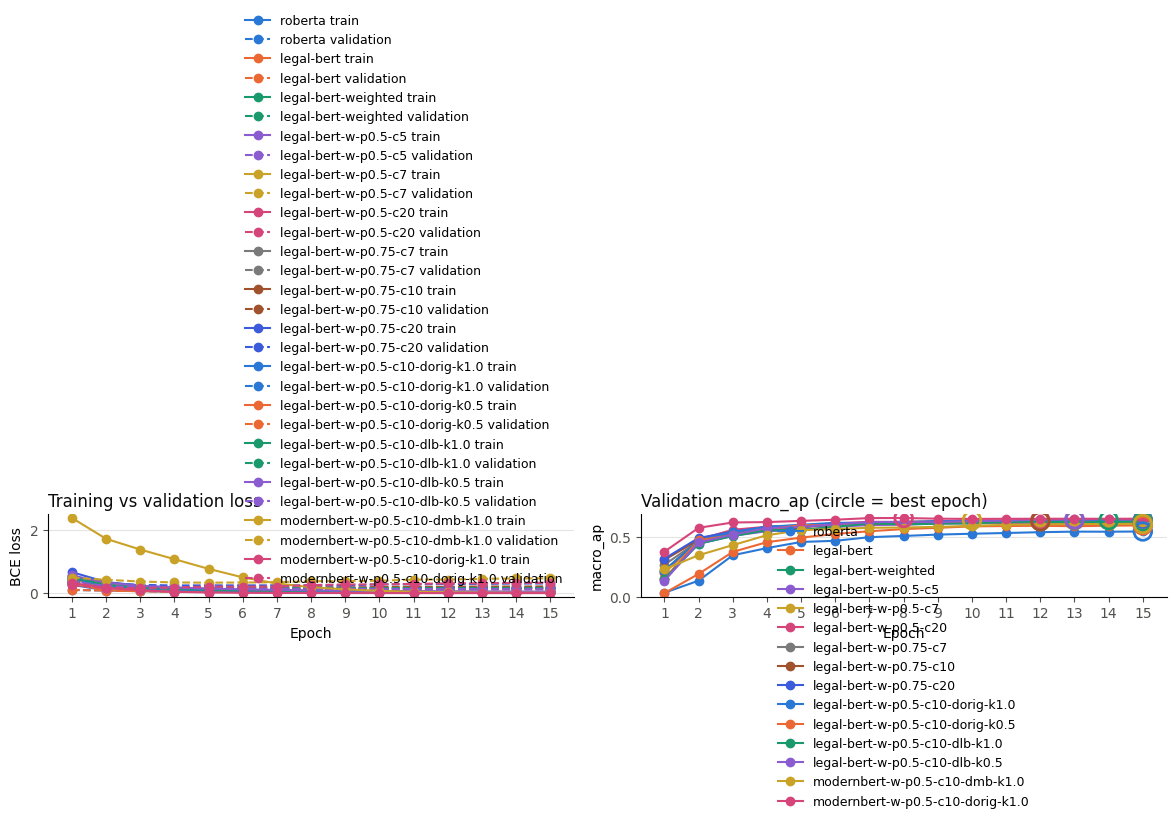

In [ ]:
summaries, histories = {}, {}
for tag in RUNS:
    if os.path.exists(f"{RESULTS_DIR}/{tag}/summary.json"):
        with open(f"{RESULTS_DIR}/{tag}/summary.json") as f:
            summaries[tag] = json.load(f)
        histories[tag] = pd.read_csv(f"{RESULTS_DIR}/{tag}/epoch_history.csv")
assert summaries, "No finished runs found. Run section 6 first."

INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e5e4e0"
PALETTE = ["#2a78d6", "#eb6834", "#1a9a6c", "#8a5cd0", "#c9a227", "#d6457a", "#2f9fb0", "#7a7a7a", "#a0522d", "#3b5bdb"]
COLORS = {tag: PALETTE[i % len(PALETTE)] for i, tag in enumerate(RUNS)}

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for tag, h in histories.items():
    axes[0].plot(h["epoch"], h["train_loss"], marker="o", color=COLORS[tag], label=f"{tag} train")
    axes[0].plot(h["epoch"], h["val_loss"], marker="o", linestyle="--", color=COLORS[tag], label=f"{tag} validation")
    axes[1].plot(h["epoch"], h[SELECT_METRIC], marker="o", color=COLORS[tag], label=tag)
    b = summaries[tag]["best_epoch"]
    axes[1].scatter([b], [h.loc[h["epoch"] == b, SELECT_METRIC].iloc[0]], s=160, facecolors="none",
                    edgecolors=COLORS[tag], linewidths=2, zorder=3)
axes[0].set_title("Training vs validation loss", loc="left", color=INK)
axes[0].set_ylabel("BCE loss")
axes[1].set_title(f"Validation {SELECT_METRIC} (circle = best epoch)", loc="left", color=INK)
axes[1].set_ylabel(SELECT_METRIC)
for ax in axes:
    ax.set_xlabel("Epoch")
    ax.set_xticks(sorted({e for h in histories.values() for e in h["epoch"]}))
    ax.grid(axis="y", color=GRID)
    ax.set_axisbelow(True)
    ax.legend(frameon=False, fontsize=9)
    for side in ["top", "right"]:
        ax.spines[side].set_visible(False)
    ax.tick_params(colors=MUTED)
if MODE == "smoke":
    fig.suptitle("SMOKE RUN (CPU, tiny subset): checks the pipeline only, the numbers are not meaningful", color="#b3261e", fontsize=10)
plt.tight_layout()
plt.savefig(f"{EXP_DIR}/{EXP_TAG}_loss_curves.png", dpi=150, bbox_inches="tight")
plt.show()

### Validation scores per epoch

In [ ]:
table = pd.concat({tag: h.set_index("epoch") for tag, h in histories.items()}, names=["model", "epoch"])
table.round(4)

train_loss  val_loss  macro_ap  \
model                            epoch                                   
roberta                          1          0.2623    0.0989    0.0333   
                                 2          0.0853    0.0809    0.1337   
                                 3          0.0643    0.0630    0.3449   
                                 4          0.0495    0.0508    0.4043   
                                 5          0.0406    0.0472    0.4553   
...                                            ...       ...       ...   
modernbert-w-p0.5-c10-dorig-k1.0 11         0.0006    0.2931    0.6478   
                                 12         0.0005    0.3099    0.6480   
                                 13         0.0003    0.3119    0.6485   
                                 14         0.0003    0.3244    0.6476   
                                 15         0.0002    0.3284    0.6489   

                                        micro_ap  micro_precision  \
model                            epoch                              
roberta                          1        0.0414           0.0000   
                                 2        0.2407           0.8667   
                                 3        0.5252           0.8576   
                                 4        0.6123           0.8370   
                                 5        0.6509           0.8191   
...                                          ...              ...   
modernbert-w-p0.5-c10-dorig-k1.0 11       0.7587           0.7892   
                                 12       0.7609           0.8031   
                                 13       0.7609           0.7985   
                                 14       0.7604           0.8037   
                                 15       0.7606           0.8107   

                                        micro_recall  micro_f1  macro_f1  
model                            epoch                                    
roberta                          1            0.0000    0.0000    0.0000  
                                 2            0.0919    0.1662    0.0590  
                                 3            0.3017    0.4464    0.1804  
                                 4            0.4054    0.5462    0.2618  
                                 5            0.4750    0.6013    0.3255  
...                                              ...       ...       ...  
modernbert-w-p0.5-c10-dorig-k1.0 11           0.6488    0.7122    0.5849  
                                 12           0.6370    0.7105    0.5858  
                                 13           0.6400    0.7105    0.5811  
                                 14           0.6370    0.7107    0.5820  
                                 15           0.6358    0.7127    0.5834  

[225 rows x 8 columns]

### Best run and epoch
Chosen on validation only (`WINNER_METRIC`). Test columns are filled only for the runs scored in an earlier milestone (RoBERTa, Legal-BERT, weighted Legal-BERT). TF-IDF reference (`experimentation/TF-IDF/03_TF-IDF_model.ipynb`): micro F1 0.591, macro F1 0.517 at 0.5.

In [ ]:
TFIDF_TEST = {"micro_f1": 0.591, "macro_f1": 0.517}   # from experimentation/TF-IDF/03_TF-IDF_model.ipynb

def run_score(s):    # validation score used to choose the winner
    if WINNER_METRIC == "contract_macro_f1":
        return s.get("val_contract", {}).get("macro_f1", float("-inf"))     # runs from before this metric existed drop out
    return s["best_val"][WINNER_METRIC]

best_tag = max(summaries, key=lambda t: run_score(summaries[t]))   # winner: validation only
rows = []
for tag, s in summaries.items():
    run = RUNS[tag]
    test = s.get("test_at_best_epoch", {})       # only present for runs whose test set was scored
    rows.append({"run": tag, "model": run["model"], "data": run.get("data", "orig"), "keep": run.get("keep", 1.0),
                 "loss": f"weighted p{run['power']} cap{run['cap']}" if run.get("power") is not None else "bce",
                 "best_epoch": s["best_epoch"],
                 "val_macro_ap": s["best_val"]["macro_ap"], "val_macro_f1": s["best_val"]["macro_f1"],
                 "val_micro_f1": s["best_val"]["micro_f1"], "val_contract_macro_f1": s.get("val_contract", {}).get("macro_f1"),
                 "test_micro_f1": test.get("micro_f1"), "test_macro_f1": test.get("macro_f1"),
                 "test_contract_macro_f1": s.get("test_contract", {}).get("macro_f1"),
                 "train_minutes": s["train_minutes"], "chosen": tag == best_tag})
comparison = pd.DataFrame(rows).assign(_score=lambda d: [run_score(summaries[t]) for t in d["run"]]).sort_values("_score", ascending=False).drop(columns="_score")
comparison = pd.concat([comparison, pd.DataFrame([{"run": "tf-idf baseline", "test_micro_f1": TFIDF_TEST["micro_f1"],
                                                    "test_macro_f1": TFIDF_TEST["macro_f1"]}])]).set_index("run")
comparison.to_csv(f"{EXP_DIR}/{EXP_TAG}_model_comparison.csv")

print(f"Chosen on validation {WINNER_METRIC}: {best_tag} ({summaries[best_tag]['model']}), epoch {summaries[best_tag]['best_epoch']}, "
      f"checkpoint: {summaries[best_tag]['checkpoint']}")
if MODE == "smoke":
    print("SMOKE RUN: the comparison only shows the pipeline works. Re-run on a GPU for real results.")
comparison.round(3)

Chosen on validation contract_macro_f1: legal-bert-w-p0.5-c10-dorig-k1.0 (nlpaueb/legal-bert-base-uncased), epoch 15, checkpoint: /content/drive/MyDrive/Accenture-1H-contract-review-challenge/models/training/15ep/legal-bert-w-p0.5-c10-dorig-k1.0/best


,model,data,keep,loss,best_epoch,val_macro_ap,val_macro_f1,val_micro_f1,val_contract_macro_f1,test_micro_f1,test_macro_f1,test_contract_macro_f1,train_minutes,chosen
run,,,,,,,,,,,,,,
legal-bert-w-p0.5-c10-dorig-k1.0,legal-bert,orig,1.0,weighted p0.5 cap10,15.0,0.632,0.623,0.696,0.771,NaN,NaN,None,13.6,True
legal-bert-w-p0.5-c10-dlb-k0.5,legal-bert,lb,0.5,weighted p0.5 cap10,13.0,0.644,0.604,0.696,0.753,NaN,NaN,None,7.8,False
legal-bert-w-p0.5-c10-dorig-k0.5,legal-bert,orig,0.5,weighted p0.5 cap10,15.0,0.625,0.602,0.681,0.748,NaN,NaN,None,9.9,False
legal-bert-w-p0.5-c10-dlb-k1.0,legal-bert,lb,1.0,weighted p0.5 cap10,15.0,0.624,0.598,0.707,0.731,NaN,NaN,None,10.4,False
modernbert-w-p0.5-c10-dorig-k1.0,modernbert,orig,1.0,weighted p0.5 cap10,8.0,0.654,0.584,0.711,0.700,NaN,NaN,None,22.2,False
modernbert-w-p0.5-c10-dmb-k1.0,modernbert,mb,1.0,weighted p0.5 cap10,15.0,0.605,0.532,0.696,0.618,NaN,NaN,None,25.5,False
roberta,roberta,orig,1.0,bce,15.0,0.542,0.512,0.697,NaN,0.692,0.524,None,13.5,False
legal-bert-w-p0.75-c7,legal-bert,orig,1.0,weighted p0.75 cap7,13.0,0.636,0.616,0.697,NaN,NaN,NaN,None,13.7,False
legal-bert-w-p0.5-c20,legal-bert,orig,1.0,weighted p0.5 cap20,12.0,0.636,0.609,0.685,NaN,NaN,NaN,None,43.1,False


### Weakest categories on validation (chosen model)
Lowest validation AP first: the categories the model finds hardest.

In [ ]:
per_cat = pd.read_csv(f"{RESULTS_DIR}/{best_tag}/val_per_category.csv", index_col=0)
per_cat.sort_values("val_ap").head(10).round(3)

,val_ap,val_positives
Affiliate License-Licensor,0.006,3
Most Favored Nation,0.130,4
Price Restrictions,0.146,8
Competitive Restriction Exception,0.175,14
Volume Restriction,0.199,19
No-Solicit Of Customers,0.306,8
Non-Disparagement,0.344,8
Affiliate License-Licensee,0.363,25
Third Party Beneficiary,0.388,9
Post-Termination Services,0.433,70


## 8. Files saved
| File | In git | Contents |
|---|---|---|
| `results/training/15ep/<run name>/summary.json` | Yes | Best epoch, validation scores (chunk-level; contract-level where computed), loss settings |
| `results/training/15ep/<run name>/epoch_history.csv` | Yes | Loss and validation scores per epoch |
| `results/training/15ep/<run name>/val_per_category.csv` | Yes | Validation AP per category |
| `results/training/15ep/experiments/modernbert_model_comparison.csv`, `modernbert_loss_curves.png` | Yes | This notebook's comparison table and loss/AP plot |
| `data/processed_lb/`, `data/processed_mb/` | No | Re-chunked data (rebuilt automatically on first use) |
| `models/training/15ep/<run name>/best/` | No (~0.5 GB each) | Best checkpoint, tokenizer, `training_info.json` (Google Drive only) |

On Colab these are under `MyDrive/Accenture-1H-contract-review-challenge/`; smoke runs go to `models/training_smoke/`. The test set is not scored here: the final model is scored once in `notebooks/pipeline/05_model_training_and_selection.ipynb`.

In [ ]:
# Results are saved to Google Drive during the run; download them from there to commit them
if IN_COLAB and MODE == "full":
    print(f"Results are on Google Drive: {RESULTS_DIR}")
    print(f"Download the run folders you trained (and experiments/) and put them in results/training/{RUN_NAME}/ in the repo.")
else:
    print("Nothing to download here." if not IN_COLAB else "Smoke run: nothing worth downloading.")

In [ ]:
# Release the GPU when the notebook has finished (full mode on Colab only). The outputs stay visible.
if IN_COLAB and MODE == "full":
    from google.colab import runtime
    runtime.unassign()

## 9. Results and limitations
**Validation results** (61 contracts; all runs: class weights p0.5 cap 10, 15 epochs)

| Run | Chunks | Chunk-level macro F1* | Macro AP* | Contract-level macro F1 | Train time (A100) |
|---|---|---|---|---|---|
| **Legal-BERT** (lr 2e-5, baseline from the data-variants notebook) | 512 tokens | 0.623 | 0.632 | **0.771** | 14 min |
| ModernBERT (lr 5e-5) | 512 tokens | 0.584 | 0.654 | 0.700 | 22 min |
| ModernBERT (lr 5e-5) | 2,048 tokens | 0.532 | 0.605 | 0.618 | 26 min |

\* Chunk-level scores of different chunkings are not directly comparable; use contract-level.

**Findings**
- On the same 512-token chunks, ModernBERT ranked clauses about as well as Legal-BERT (macro AP 0.654 vs 0.632) but was clearly worse at the 0.5 threshold, at chunk and contract level. Legal-domain pretraining mattered more than a newer architecture.
- Longer chunks made ModernBERT worse, not better: with 2,048 tokens a chunk mixes many clauses, and there are about 4 times fewer training examples.
- The pipeline therefore keeps Legal-BERT on 512-token chunks.

**Limitations**
- One run each, with one learning rate (5e-5) and no tuning; a tuned ModernBERT (or a threshold other than 0.5) might close part of the gap.
- ModernBERT's best epoch on 512-token chunks was 8 of 15, so it may also need fewer epochs or more regularization.